# 28 · Seasons, anomalies and lagged relationships

**Time:** 50 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** build support-aware regional series; remove a training-period seasonal baseline; interpret lag correlations cautiously.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=28_seasfire_seasons_lags.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Compare two seasonal calendars

Fire seasons can differ across hemispheres. Compute a strict spatial sum of burned hectares (any missing
cell makes that period unavailable), and area-weighted means of intensive weather variables.
The baseline below uses **2002–2015**. The later **2016–2021** years are held out.
Nominal bins are indexed 0–45 within each year; their timestamps and durations remain available.

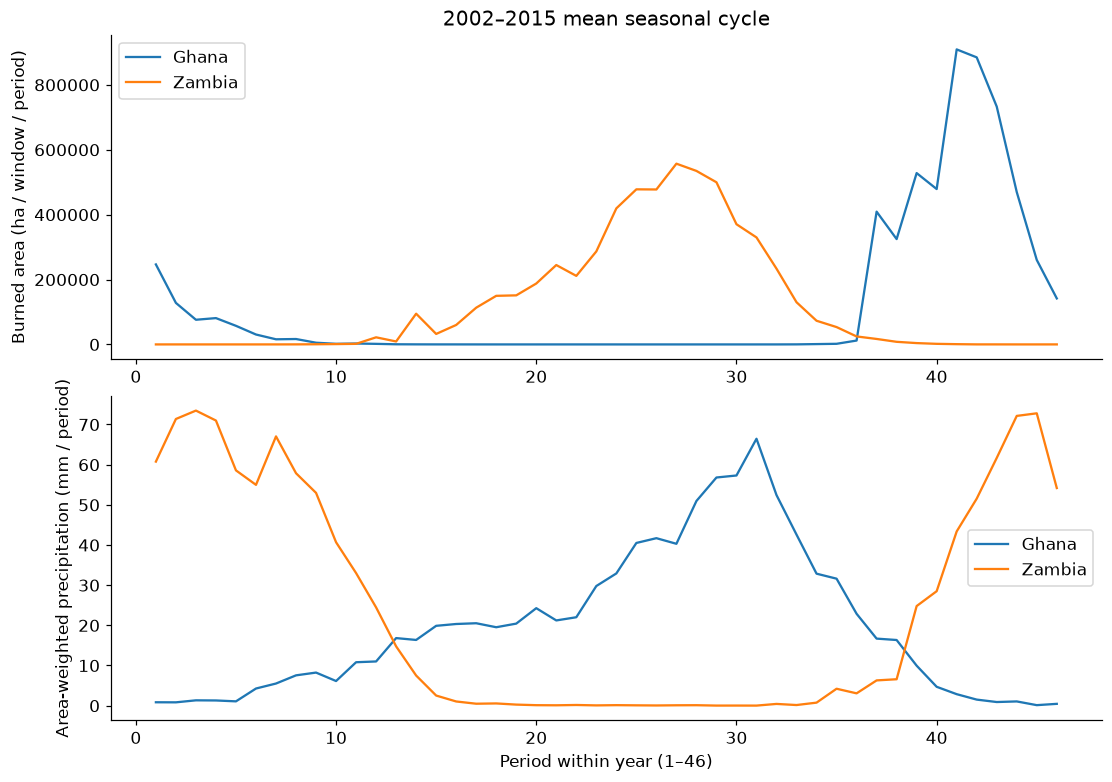

In [2]:
from seasfire import load_seasfire, spatial_series, seasonal_anomaly, lag_correlation
fig,axes=plt.subplots(2,1,figsize=(10,7),layout='constrained')
for key in ['ghana','zambia']:
    d=load_seasfire(key)
    train=(d['year']>=2002)&(d['year']<=2015)
    for ax,var in zip(axes,['gwis_ba','tp']):
        values=spatial_series(d,var)
        _,baseline=seasonal_anomaly(values,d['bin'],train)
        ax.plot(np.arange(1,47),baseline,label=key.title())
axes[0].set(ylabel='Burned area (ha / window / period)',title='2002–2015 mean seasonal cycle')
axes[1].set(xlabel='Period within year (1–46)',ylabel='Area-weighted precipitation (mm / period)')
for ax in axes:ax.legend()
plt.show()

## 2. Separate seasonality from anomalies

An association between dry weather and fire can largely reflect their common seasonal calendar.
Subtract the training-period average for each bin. Positive lag here pairs **driver[t−lag] with fire[t]**.
A lag of one is a source-bin step, not exactly eight days when crossing a year boundary.
The split is chronological, and a pair is used only if both its times are in the same split.

Raw, train valid pairs by lag: [644, 643, 642, 641, 640, 639, 638]
Anomaly, train valid pairs by lag: [644, 643, 642, 641, 640, 639, 638]
Anomaly, held out valid pairs by lag: [276, 275, 274, 273, 272, 271, 270]


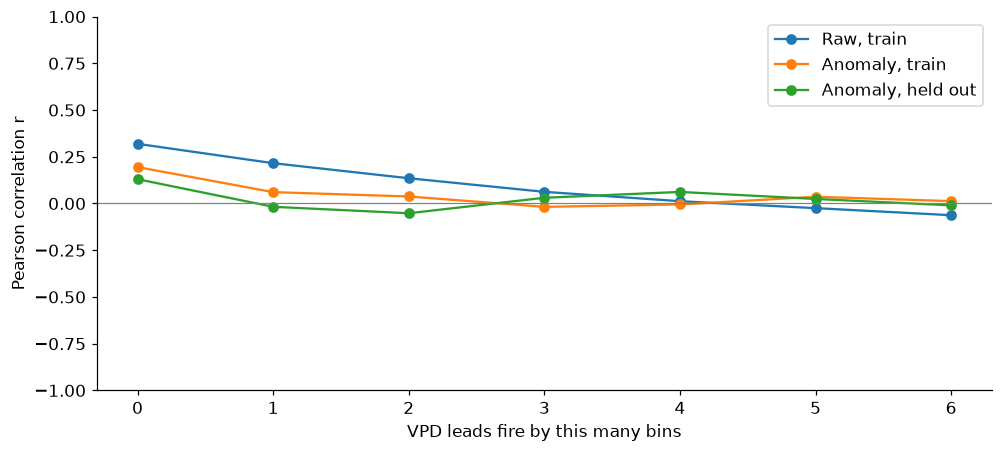

In [3]:
d=load_seasfire('zambia')
train=(d['year']>=2002)&(d['year']<=2015)
test=d['year']>=2016
fire=spatial_series(d,'gwis_ba'); vpd=spatial_series(d,'vpd')
fire_anom,_=seasonal_anomaly(fire,d['bin'],train)
vpd_anom,_=seasonal_anomaly(vpd,d['bin'],train)
lags=np.arange(7)
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
for title,x,y,split in [('Raw, train',vpd,fire,train),('Anomaly, train',vpd_anom,fire_anom,train),
                        ('Anomaly, held out',vpd_anom,fire_anom,test)]:
    results=[lag_correlation(x,y,int(lag),split) for lag in lags]
    ax.plot(lags,[r[0] for r in results],marker='o',label=title)
    print(title,'valid pairs by lag:',[r[1] for r in results])
ax.axhline(0,color='grey',linewidth=.8)
ax.set(xlabel='VPD leads fire by this many bins',ylabel='Pearson correlation r',ylim=(-1,1))
ax.legend();plt.show()

## 3. A descriptive calculation is not a forecast

These correlations have no independent-sample significance claim: adjacent periods and neighboring cells
are dependent, multiple lags were inspected, and omitted drivers remain. Shared seasonality, fuel growth,
land use, ignition and fire management can all matter. Harmonized variables can incorporate interpolation;
a real forecast must audit when each input was actually available. A chronological split alone cannot fix that.

For a forecast study, choose the lag and model on training data, reserve a final untouched test period,
compare with a seasonal baseline, and use dependence-aware uncertainty estimates.
Do not select the best held-out lag and report it as an unbiased final score.

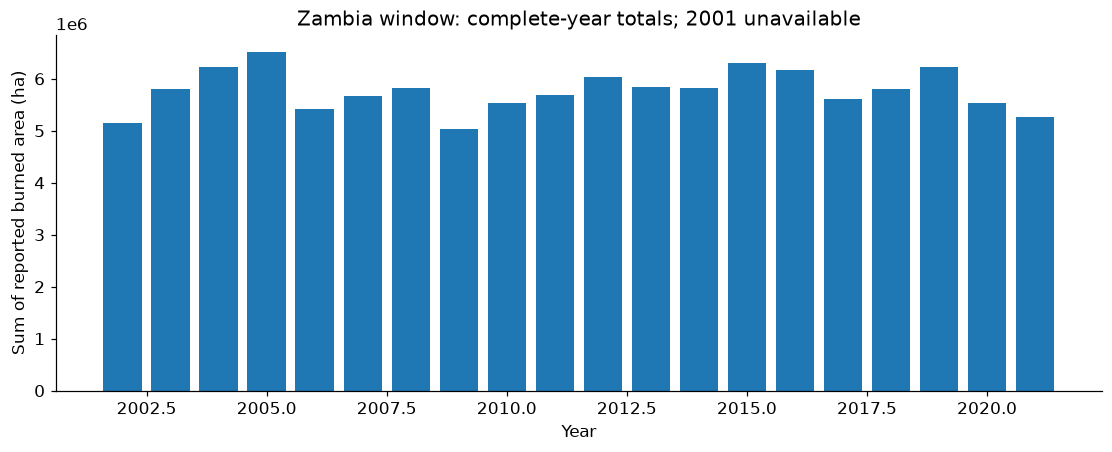

Missing annual totals: [2001]


In [4]:
years=np.unique(d['year'])
annual=np.array([np.sum(fire[d['year']==y]) if np.isfinite(fire[d['year']==y]).all() else np.nan for y in years])
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
ax.bar(years,annual)
ax.set(xlabel='Year',ylabel='Sum of reported burned area (ha)',title='Zambia window: complete-year totals; 2001 unavailable')
plt.show()
print('Missing annual totals:',years[~np.isfinite(annual)])

## 4. Connect to an impact question responsibly

SeasFire helps describe environmental conditions. Smoke exposure needs emissions, transport, population
and measurements; water-quality impacts need catchments, runoff and observations; food-security impacts
need crop calendars, yields, livelihoods and local knowledge. These cubes do not directly measure those outcomes.
Use [IPCC Africa context](https://www.ipcc.ch/report/ar6/wg2/chapter/chapter-9/) and local expertise when framing a project.

## Try it yourself

Repeat the lag plot with precipitation or NDVI. Record the sign convention, baseline, valid-pair counts and two alternative explanations.

## Check your reasoning

A lagged correlation is a descriptive association. It does not establish a causal mechanism, climate attribution or operational forecast skill.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [SeasFire Cube v0.4, Alonso et al. (2024)](https://doi.org/10.5281/zenodo.13834057), CC-BY-4.0. Spatial subsets and browser repackaging by this course; no spatial resampling.
- [Karasante, Alonso, Prapas, Ahuja, Carvalhais & Papoutsis (2025), SeasFire cube — a multivariate dataset for global wildfire modeling](https://doi.org/10.1038/s41597-025-04546-3), Scientific Data 12, 368.
- [ESA Open Science Catalog / EarthCODE](https://opensciencedata.esa.int/products/seasfire-cube/item), public SeasFire v0.4 mirror. Inputs used: GWIS burned area, ECMWF/Copernicus ERA5, NASA MODIS MOD13C1 v6 NDVI, and SeasFire derived VPD/cell area.
- [Exact source objects, SHA256 checksums, extraction windows and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/seasfire-provenance.json).
- [Söchting, Scheuermann, Montero & Mahecha (2025), Interactive Earth system data cube visualization in Jupyter notebooks](https://doi.org/10.1080/20964471.2025.2471646), Big Earth Data, 1–15. [LexCube 2.0.1](https://github.com/msoechting/lexcube), Maximilian Söchting and contributors, GPL-3.0-or-later.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [5]:
print('LESSON COMPLETE: 28_seasfire_seasons_lags')

LESSON COMPLETE: 28_seasfire_seasons_lags
